In [6]:
import yaml
import json
import numpy as np
from matplotlib import pyplot as plt

# --- Custom Utility Module ---
from flux_history import FluxHistory
from mineral_utils import Paleodetector, slice_spectrum_etch
import OptimusPrimus as OP

In [7]:
MINERAL_LIBRARY = yaml.safe_load(open('Data/mineral_library.yaml', 'r'))

mineral_name =  "Obsidian"

total_age_kyr = 3200.

overburden_history = {}

flux_history = FluxHistory()

In [8]:
mineral_config = MINERAL_LIBRARY.get(mineral_name)

mineral = Paleodetector(mineral_config, total_age_kyr=total_age_kyr, flux_history=flux_history, overburden_history=overburden_history)
x_bins, total_fission_tracks = mineral.integrate_fission_spectrum()


Interpolating overburden history...
Initialized Paleodetector: Obsidian
Calculating spontaneous fission background...


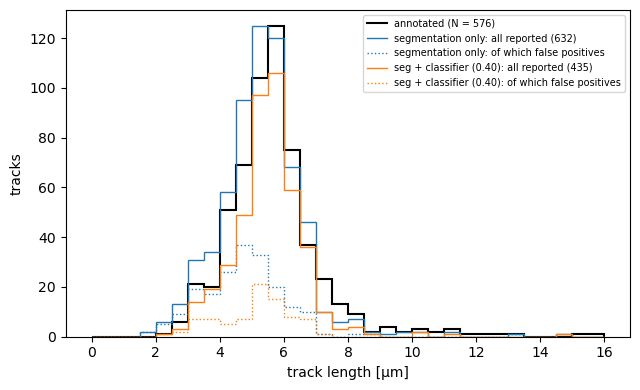

In [9]:
LEG = "Data/models/seg_Training-obsidian_n59-9f0fcd_MAnet-efficientnet-b7_ep200-bs2-lr3e-04-Dice-F1_legacy"
base = LEG + "/" + LEG.split("/")[-1]
logs = {
    "segmentation only": json.load(open(base + "_st0.1_detection_logs.json")),
    "seg + classifier (0.40)": json.load(open(base + "__cls-legacy-mixed_pt0.1_efficientnet-b0_ep80-bs64-lr3e-05-pw0.7_st0.1_ct0.55_detection_logs.json")),
}

first = next(iter(logs.values()))
area = first["val_area_cm2"]
edges = np.arange(0, 16.5, 0.5)
edges_nm = edges * 1e3                               
gt = np.array([r["len_um"] for r in first["gt_log"]])


fig, ax = plt.subplots(figsize=(6.5, 4))
n, _ = np.histogram(gt, edges)

ax.stairs(n, edges, color="k", lw=1.5, label=f"annotated (N = {len(gt)})")
for (name, L), c in zip(logs.items(), ("C0", "C1")):
    rep = np.array([r["len_um"] for r in L["pred_log"]])
    tp = np.array([r["is_true_positive"] for r in L["pred_log"]])
    ax.stairs(np.histogram(rep, edges)[0], edges, color=c, label=f"{name}: all reported ({len(rep)})")
    ax.stairs(np.histogram(rep[~tp], edges)[0], edges, color=c, ls=":", label=f"{name}: of which false positives")
ax.set_xlabel("track length [µm]"); ax.set_ylabel("tracks")
ax.legend(fontsize=7); plt.tight_layout(); 
plt.savefig("Papers/OP/obsidian_track_length_distribution.pdf", dpi=300)
plt.show()

In [10]:
edges_nm_mids = (edges_nm[1:] + edges_nm[:-1]) / 2

A = logs["seg + classifier (0.40)"]["val_area_cm2"]
desc = OP.detection_descriptor(logs["seg + classifier (0.40)"], edges_nm)
model = OP.detection_model(desc)
n_obs = np.histogram(rep, edges)[0]

slices = []
mu_ths = []

for _ in range(100):
    sliced = slice_spectrum_etch(total_fission_tracks, sample_area_cm2=A, sample_density_g_cm3=2.4,
                                removed_nm=4000, v_ratio=2.5, lateral_ratio=1.,
                                min_width_nm=0.375 * 4 * 1e3, out_bins=edges_nm)
    mu_th = OP.fold_detection(sliced, model, A)
    slices.append(sliced)
    mu_ths.append(mu_th)

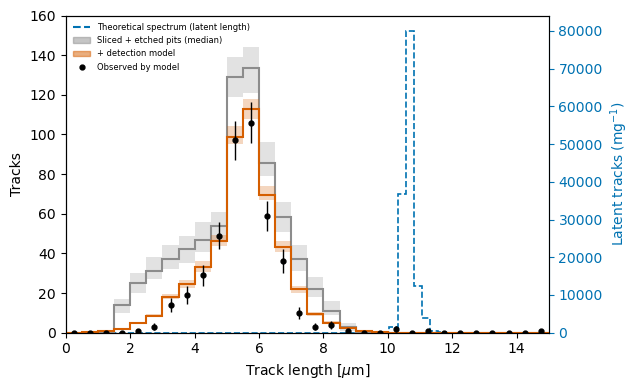

In [11]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

C_SLICE, C_FOLD, C_TH = "0.55", "#D55E00", "#0072B2"      # grey, vermillion, blue (colour-blind safe)
x = edges_nm / 1e3
mids_um = 0.5 * (x[1:] + x[:-1])

def stairs_band(ax, runs, color):
    """Median as stairs, 16-84 % of the runs as a step band on the same edges."""
    lo, med, hi = np.percentile(runs, [16, 50, 84], axis=0)
    ax.fill_between(x, np.append(lo, lo[-1]), np.append(hi, hi[-1]), step="post", color=color, alpha=0.25, lw=0)
    ax.stairs(med, x, color=color, lw=1.5)

fig, ax = plt.subplots(figsize=(6.5, 4))
stairs_band(ax, slices, C_SLICE)
stairs_band(ax, mu_ths, C_FOLD)
ax.errorbar(mids_um, n_obs, yerr=np.sqrt(np.maximum(n_obs, 1)), fmt="o", color="k", ms=3.5, lw=1, capsize=0)
ax.set_xlabel(r"Track length [$\mu$m]")
ax.set_ylabel("Tracks")
ax.set_xlim(x[0], 15)
ax.set_ylim(bottom=0, top=160)

ax2 = ax.twinx()
theory_w_um = np.diff(x_bins) / 1e3
ax2.stairs(total_fission_tracks / theory_w_um, x_bins / 1e3, color=C_TH, lw=1.2, ls="--")
ax2.set_ylabel(rf"Latent tracks (mg$^{{-1}}$)", color=C_TH)
ax2.tick_params(axis="y", colors=C_TH)
ax2.spines["right"].set_color(C_TH)
ax2.set_ylim(bottom=0)

ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)   # data drawn above the theory curve

handles = [Line2D([], [], color=C_TH, ls="--", label="Theoretical spectrum (latent length)"),
           Patch(facecolor=C_SLICE, alpha=0.5, edgecolor=C_SLICE, label="Sliced + etched pits (median)"),
           Patch(facecolor=C_FOLD, alpha=0.5, edgecolor=C_FOLD, label="+ detection model"),
           Line2D([], [], color="k", marker="o", ls="", ms=3.5, label=rf"Observed by model")]
ax.legend(handles=handles, fontsize=6, frameon=False, loc="upper left")
plt.tight_layout() 
plt.savefig("Papers/OP/obsidian_spectrum.pdf", dpi=300)
plt.show()
